In [ ]:
# Driver Drowsiness Detection
## 04 — ResNet18 Transfer Learning

### Objective

Train a pretrained ResNet18 model to classify driver images into:

- Active (label 0)
- Fatigue (label 1)

### Experimental methodology

1. Load the finalized manifest-defined dataset.
2. Apply the validated image preprocessing pipeline.
3. Load pretrained ResNet18 weights.
4. Train the new classification head.
5. Fine-tune the final residual block.
6. Select the best checkpoint using validation loss.
7. Evaluate the selected model on the held-out test set.

### Evaluation metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- Training and validation loss

In [1]:
import os

# Keep pretrained model weights on E: rather than C:
os.environ["TORCH_HOME"] = r"E:\Driver-Drowsiness\torch-cache"

from pathlib import Path
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torchvision import models, transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select GPU
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

DATA_DIR = Path(r"E:\Driver-Drowsiness\data\raw")
MODEL_DIR = Path(r"E:\Driver-Drowsiness\models\resnet18_transfer")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
Path(os.environ["TORCH_HOME"]).mkdir(parents=True, exist_ok=True)

print("Python environment:", __import__("sys").executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Dataset exists:", DATA_DIR.exists())
print("Device:", device)
print("Model output directory:", MODEL_DIR)
print("Torch cache:", torch.hub.get_dir())

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )
else:
    raise RuntimeError(
        "CUDA is unavailable. Do not start training until GPU is verified."
    )

Python environment: E:\Driver-Drowsiness\environment\python.exe
PyTorch: 2.14.0+cu130
Torchvision: 0.29.0+cu130
Dataset exists: True
Device: cuda:0
Model output directory: E:\Driver-Drowsiness\models\resnet18_transfer
Torch cache: E:\Driver-Drowsiness\torch-cache\hub
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU
VRAM: 4.0 GB


In [2]:
def load_manifest(split):
    manifest_path = DATA_DIR / f"{split}.txt"

    records = []

    with open(
        manifest_path, "r", encoding="utf-8", errors="ignore"
    ) as file:
        for line in file:
            parts = line.strip().split()

            if not parts:
                continue

            image_path = DATA_DIR / parts[0].replace("\\", "/")
            label = int(parts[-1])

            if label not in (0, 1):
                raise ValueError(f"Unexpected label: {label}")

            records.append({
                "path": str(image_path),
                "label": label,
                "class": "Active" if label == 0 else "Fatigue"
            })

    df = pd.DataFrame(records)

    missing = [
        path for path in df["path"]
        if not Path(path).is_file()
    ]

    if missing:
        raise FileNotFoundError(
            f"{len(missing)} image files are missing from {split}."
        )

    return df


train_df = load_manifest("train")
val_df = load_manifest("val")
test_df = load_manifest("test")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining labels:")
print(train_df["class"].value_counts())

Train: 6384
Validation: 1715
Test: 909
Total: 9008

Training labels:
class
Active     3192
Fatigue    3192
Name: count, dtype: int64


In [3]:
IMAGE_SIZE = 224
BATCH_SIZE = 16

class Letterbox:
    def __init__(self, size, fill=(0, 0, 0)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")
        image.thumbnail(
            (self.size, self.size),
            Image.Resampling.LANCZOS
        )

        canvas = Image.new(
            "RGB", (self.size, self.size), self.fill
        )

        x = (self.size - image.width) // 2
        y = (self.size - image.height) // 2

        canvas.paste(image, (x, y))
        return canvas


normalization = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

train_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5, fill=(0, 0, 0)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    normalization
])

eval_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.ToTensor(),
    normalization
])

print("ResNet18 transforms ready!")

ResNet18 transforms ready!


In [4]:
class DrowsinessDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["path"]) as source:
            image = source.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            int(row["label"]), dtype=torch.long
        )

        return image, label


train_dataset = DrowsinessDataset(train_df, train_transform)
val_dataset = DrowsinessDataset(val_df, eval_transform)
test_dataset = DrowsinessDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 399
Validation batches: 108
Test batches: 57


In [5]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

images = images.to(device)
labels = labels.to(device)

print("Image device:", images.device)
print("Label device:", labels.device)

del images, labels

Image shape: torch.Size([16, 3, 224, 224])
Label shape: torch.Size([16])
Image device: cuda:0
Label device: cuda:0


In [6]:
weights = models.ResNet18_Weights.DEFAULT

resnet = models.resnet18(weights=weights)

# Replace the original 1000-class ImageNet classifier
# with our two-class classifier.
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, 2)

# Freeze all pretrained parameters initially
for parameter in resnet.parameters():
    parameter.requires_grad = False

# Only the new classification head is trainable in Stage 1
for parameter in resnet.fc.parameters():
    parameter.requires_grad = True

resnet = resnet.to(device)

total_params = sum(p.numel() for p in resnet.parameters())
trainable_params = sum(
    p.numel() for p in resnet.parameters()
    if p.requires_grad
)

print("Architecture: ResNet18")
print("Pretrained weights:", weights)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters (Stage 1): {trainable_params:,}")
print("Model device:", next(resnet.parameters()).device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to E:\Driver-Drowsiness\torch-cache\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 10.7MB/s]


Architecture: ResNet18
Pretrained weights: ResNet18_Weights.IMAGENET1K_V1
Total parameters: 11,177,538
Trainable parameters (Stage 1): 1,026
Model device: cuda:0


In [7]:
resnet.eval()

dummy_input = torch.randn(
    2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device
)

with torch.inference_mode():
    output = resnet(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Output device:", output.device)

assert output.shape == (2, 2)
assert output.device.type == "cuda"

print("ResNet18 GPU forward pass: SUCCESS")

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 2])
Output device: cuda:0
ResNet18 GPU forward pass: SUCCESS


In [8]:
# Freeze the pretrained backbone
for parameter in resnet.parameters():
    parameter.requires_grad = False

# Train only the new two-class classifier
for parameter in resnet.fc.parameters():
    parameter.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    resnet.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

HEAD_EPOCHS = 3

BEST_HEAD_PATH = MODEL_DIR / "stage1_best_head.pt"
LAST_HEAD_PATH = MODEL_DIR / "stage1_last_checkpoint.pt"

print("Stage 1: Classifier head training")
print("Trainable parameters:", sum(
    p.numel() for p in resnet.parameters()
    if p.requires_grad
))
print("Learning rate: 0.001")
print("Epochs:", HEAD_EPOCHS)
print("Device:", next(resnet.parameters()).device)

Stage 1: Classifier head training
Trainable parameters: 1026
Learning rate: 0.001
Epochs: 3
Device: cuda:0


In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def train_head_one_epoch(model, loader, criterion, optimizer, device):
    # Keep the frozen backbone, including BatchNorm statistics, in eval mode
    model.eval()
    model.fc.train()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in tqdm(loader, desc="Training head", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        all_predictions.extend(outputs.argmax(1).detach().cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_predictions)
    }


@torch.inference_mode()
def evaluate_resnet(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in tqdm(loader, desc="Validation", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        all_predictions.extend(outputs.argmax(1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "fatigue_precision": precision_score(
            all_labels, all_predictions, pos_label=1, zero_division=0
        ),
        "fatigue_recall": recall_score(
            all_labels, all_predictions, pos_label=1, zero_division=0
        ),
        "fatigue_f1": f1_score(
            all_labels, all_predictions, pos_label=1, zero_division=0
        )
    }

print("Training and evaluation functions ready!")

Training and evaluation functions ready!


In [10]:
import time

history_head = []
best_head_val_loss = float("inf")
start_time = time.time()

for epoch in range(1, HEAD_EPOCHS + 1):
    epoch_start = time.time()

    train_metrics = train_head_one_epoch(
        resnet, train_loader, criterion, optimizer, device
    )

    val_metrics = evaluate_resnet(
        resnet, val_loader, criterion, device
    )

    record = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_fatigue_precision": val_metrics["fatigue_precision"],
        "val_fatigue_recall": val_metrics["fatigue_recall"],
        "val_fatigue_f1": val_metrics["fatigue_f1"]
    }

    history_head.append(record)

    checkpoint = {
        "stage": "classifier_head",
        "epoch": epoch,
        "model_state_dict": resnet.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_loss": val_metrics["loss"],
        "history": history_head
    }

    torch.save(checkpoint, LAST_HEAD_PATH)

    if val_metrics["loss"] < best_head_val_loss:
        best_head_val_loss = val_metrics["loss"]
        torch.save(checkpoint, BEST_HEAD_PATH)
        saved_message = "Best checkpoint saved."
    else:
        saved_message = "Best checkpoint unchanged."

    print(f"\nEpoch {epoch}/{HEAD_EPOCHS}")
    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train accuracy: {train_metrics['accuracy']:.4f}"
    )
    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f}"
    )
    print(
        f"Fatigue precision: {val_metrics['fatigue_precision']:.4f} | "
        f"Recall: {val_metrics['fatigue_recall']:.4f} | "
        f"F1: {val_metrics['fatigue_f1']:.4f}"
    )
    print(f"Epoch time: {time.time() - epoch_start:.1f} seconds")
    print(saved_message)

print(f"\nStage 1 completed in {(time.time() - start_time)/60:.2f} minutes.")
print("Best head checkpoint:", BEST_HEAD_PATH)

Training head:   0%|          | 0/399 [00:00<?, ?it/s]

Validation:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 1/3
Train loss: 0.4836 | Train accuracy: 0.7511
Val loss: 0.4233 | Val accuracy: 0.7994
Fatigue precision: 0.8166 | Recall: 0.7372 | F1: 0.7749
Epoch time: 641.3 seconds
Best checkpoint saved.


Training head:   0%|          | 0/399 [00:00<?, ?it/s]

Validation:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 2/3
Train loss: 0.4045 | Train accuracy: 0.8004
Val loss: 0.4170 | Val accuracy: 0.7738
Fatigue precision: 0.8673 | Recall: 0.6102 | F1: 0.7164
Epoch time: 462.7 seconds
Best checkpoint saved.


Training head:   0%|          | 0/399 [00:00<?, ?it/s]

Validation:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 3/3
Train loss: 0.3982 | Train accuracy: 0.7978
Val loss: 0.4160 | Val accuracy: 0.7749
Fatigue precision: 0.7071 | Recall: 0.8867 | F1: 0.7867
Epoch time: 447.9 seconds
Best checkpoint saved.

Stage 1 completed in 25.87 minutes.
Best head checkpoint: E:\Driver-Drowsiness\models\resnet18_transfer\stage1_best_head.pt


In [11]:
checkpoint = torch.load(
    BEST_HEAD_PATH,
    map_location=device,
    weights_only=True
)

resnet.load_state_dict(checkpoint["model_state_dict"])
resnet = resnet.to(device)

print("Best head checkpoint restored.")
print("Best epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])
print("Model device:", next(resnet.parameters()).device)

Best head checkpoint restored.
Best epoch: 3
Validation loss: 0.41595311569316046
Model device: cuda:0


In [12]:
# Restore the best Stage 1 checkpoint before fine-tuning
checkpoint = torch.load(
    BEST_HEAD_PATH,
    map_location=device,
    weights_only=True
)

resnet.load_state_dict(checkpoint["model_state_dict"])
resnet.to(device)

# Freeze every parameter first
for parameter in resnet.parameters():
    parameter.requires_grad = False

# Unfreeze the final residual block
for parameter in resnet.layer4.parameters():
    parameter.requires_grad = True

# Unfreeze the new classifier
for parameter in resnet.fc.parameters():
    parameter.requires_grad = True

# Different learning rates for pretrained features and classifier
optimizer = optim.AdamW(
    [
        {
            "params": resnet.layer4.parameters(),
            "lr": 0.0001
        },
        {
            "params": resnet.fc.parameters(),
            "lr": 0.0005
        }
    ],
    weight_decay=0.0001
)

criterion = nn.CrossEntropyLoss()

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-6
)

FINETUNE_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 2

BEST_FINETUNE_PATH = MODEL_DIR / "stage2_best_resnet18.pt"
LAST_FINETUNE_PATH = MODEL_DIR / "stage2_last_checkpoint.pt"

trainable_params = sum(
    p.numel()
    for p in resnet.parameters()
    if p.requires_grad
)

print("Stage 2 configured successfully.")
print("Trainable parameters:", f"{trainable_params:,}")
print("Layer4 learning rate:", optimizer.param_groups[0]["lr"])
print("Classifier learning rate:", optimizer.param_groups[1]["lr"])
print("Device:", next(resnet.parameters()).device)

Stage 2 configured successfully.
Trainable parameters: 8,394,754
Layer4 learning rate: 0.0001
Classifier learning rate: 0.0005
Device: cuda:0


In [13]:
def train_finetune_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    # Keep the frozen pretrained layers in evaluation mode
    model.conv1.eval()
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    # Train only the final residual block and classifier
    model.layer4.train()
    model.fc.train()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in tqdm(
        loader, desc="Fine-tuning", leave=False
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        # Limit excessively large gradient updates
        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad],
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        all_predictions.extend(
            outputs.argmax(dim=1).detach().cpu().tolist()
        )
        all_labels.extend(labels.cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_predictions)
    }


print("Fine-tuning function ready.")

Fine-tuning function ready.


In [14]:
import time

history_finetune = []
best_ft_val_loss = float("inf")
epochs_without_improvement = 0

training_start = time.time()

for epoch in range(1, FINETUNE_EPOCHS + 1):
    epoch_start = time.time()

    train_metrics = train_finetune_one_epoch(
        resnet, train_loader, criterion, optimizer, device
    )

    val_metrics = evaluate_resnet(
        resnet, val_loader, criterion, device
    )

    # Adjust both learning rates using validation loss
    scheduler.step(val_metrics["loss"])

    current_lrs = [
        group["lr"] for group in optimizer.param_groups
    ]

    history_finetune.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_fatigue_precision": val_metrics["fatigue_precision"],
        "val_fatigue_recall": val_metrics["fatigue_recall"],
        "val_fatigue_f1": val_metrics["fatigue_f1"],
        "layer4_lr": current_lrs[0],
        "classifier_lr": current_lrs[1]
    })

    checkpoint = {
        "stage": "fine_tuning",
        "epoch": epoch,
        "model_state_dict": resnet.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "val_loss": val_metrics["loss"],
        "history": history_finetune
    }

    torch.save(checkpoint, LAST_FINETUNE_PATH)

    if val_metrics["loss"] < best_ft_val_loss:
        best_ft_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0

        torch.save(checkpoint, BEST_FINETUNE_PATH)
        status = "Best checkpoint saved."
    else:
        epochs_without_improvement += 1
        status = (
            f"No improvement: "
            f"{epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}"
        )

    print(f"\nEpoch {epoch}/{FINETUNE_EPOCHS}")
    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train accuracy: {train_metrics['accuracy']:.4f}"
    )
    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f}"
    )
    print(
        f"Fatigue precision: {val_metrics['fatigue_precision']:.4f} | "
        f"Recall: {val_metrics['fatigue_recall']:.4f} | "
        f"F1: {val_metrics['fatigue_f1']:.4f}"
    )
    print(
        f"Learning rates — layer4: {current_lrs[0]:.7f}, "
        f"classifier: {current_lrs[1]:.7f}"
    )
    print(f"Epoch time: {time.time() - epoch_start:.1f} seconds")
    print(status)

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered.")
        break

history_ft_df = pd.DataFrame(history_finetune)
history_ft_df.to_csv(
    MODEL_DIR / "stage2_training_history.csv",
    index=False
)

print(
    f"\nFine-tuning finished in "
    f"{(time.time() - training_start) / 60:.2f} minutes."
)
print("Best validation loss:", best_ft_val_loss)
print("Best checkpoint:", BEST_FINETUNE_PATH)

Fine-tuning:   0%|          | 0/399 [00:00<?, ?it/s]

Validation:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 1/5
Train loss: 0.4113 | Train accuracy: 0.8391
Val loss: 0.2580 | Val accuracy: 0.8915
Fatigue precision: 0.8940 | Recall: 0.8717 | F1: 0.8827
Learning rates — layer4: 0.0001000, classifier: 0.0005000
Epoch time: 443.7 seconds
Best checkpoint saved.


Fine-tuning:   0%|          | 0/399 [00:00<?, ?it/s]

Validation:   0%|          | 0/108 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 4/5
Train loss: 0.2250 | Train accuracy: 0.9192
Val loss: 0.1804 | Val accuracy: 0.9329
Fatigue precision: 0.9377 | Recall: 0.9178 | F1: 0.9276
Learning rates — layer4: 0.0001000, classifier: 0.0005000
Epoch time: 430.8 seconds
Best checkpoint saved.


Fine-tuning:   0%|          | 0/399 [00:00<?, ?it/s]

Validation:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 5/5
Train loss: 0.2062 | Train accuracy: 0.9243
Val loss: 0.1961 | Val accuracy: 0.9318
Fatigue precision: 0.9214 | Recall: 0.9340 | F1: 0.9276
Learning rates — layer4: 0.0001000, classifier: 0.0005000
Epoch time: 440.9 seconds
No improvement: 1/2

Fine-tuning finished in 36.10 minutes.
Best validation loss: 0.18036112777139374
Best checkpoint: E:\Driver-Drowsiness\models\resnet18_transfer\stage2_best_resnet18.pt


In [15]:
checkpoint = torch.load(
    BEST_FINETUNE_PATH,
    map_location=device,
    weights_only=True
)

resnet.load_state_dict(checkpoint["model_state_dict"])
resnet.to(device)
resnet.eval()

print("Best fine-tuned checkpoint restored.")
print("Best epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])
print("Model device:", next(resnet.parameters()).device)

Best fine-tuned checkpoint restored.
Best epoch: 4
Validation loss: 0.18036112777139374
Model device: cuda:0


In [16]:
import numpy as np
import pandas as pd
from IPython.display import display as show_table

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Ensure we're evaluating the restored best checkpoint
resnet.eval()

y_val_resnet = []
p_val_resnet = []

# Collect predictions on validation data only
with torch.inference_mode():
    for images, labels in tqdm(
        val_loader, desc="ResNet18 validation"
    ):
        images = images.to(device, non_blocking=True)

        outputs = resnet(images)
        probabilities = torch.softmax(outputs, dim=1)

        y_val_resnet.extend(labels.numpy().tolist())
        p_val_resnet.extend(
            probabilities[:, 1].cpu().numpy().tolist()
        )

y_val_resnet = np.array(y_val_resnet)
p_val_resnet = np.array(p_val_resnet)

print("Validation samples:", len(y_val_resnet))
print("Actual Active:", int((y_val_resnet == 0).sum()))
print("Actual Fatigue:", int((y_val_resnet == 1).sum()))
print("Validation prediction collection complete.")

ResNet18 validation:   0%|          | 0/108 [00:00<?, ?it/s]

Validation samples: 1715
Actual Active: 912
Actual Fatigue: 803
Validation prediction collection complete.


In [17]:
thresholds = [
    0.20, 0.25, 0.30, 0.35, 0.40,
    0.45, 0.50, 0.55, 0.60, 0.65, 0.70
]

threshold_results_resnet = []

for threshold in thresholds:
    predictions = (
        p_val_resnet >= threshold
    ).astype(int)

    threshold_results_resnet.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val_resnet, predictions
        ),
        "Fatigue Precision": precision_score(
            y_val_resnet, predictions,
            pos_label=1, zero_division=0
        ),
        "Fatigue Recall": recall_score(
            y_val_resnet, predictions,
            pos_label=1, zero_division=0
        ),
        "Fatigue F1": f1_score(
            y_val_resnet, predictions,
            pos_label=1, zero_division=0
        ),
        "Predicted Fatigue": int(predictions.sum())
    })

threshold_df_resnet = pd.DataFrame(
    threshold_results_resnet
)

show_table(
    threshold_df_resnet
    .sort_values("Fatigue F1", ascending=False)
    .round(4)
)

,Threshold,Accuracy,Fatigue Precision,Fatigue Recall,Fatigue F1,Predicted Fatigue
6,0.50,0.9329,0.9377,0.9178,0.9276,786
5,0.45,0.9312,0.9319,0.9203,0.9261,793
4,0.40,0.9289,0.9209,0.9278,0.9243,809
3,0.35,0.9277,0.9145,0.9328,0.9236,819
7,0.55,0.9294,0.9394,0.9078,0.9234,776
1,0.25,0.9254,0.8966,0.9502,0.9226,851
8,0.60,0.9294,0.9499,0.8966,0.9225,758
2,0.30,0.9254,0.9042,0.9402,0.9219,835
9,0.65,0.9277,0.9557,0.8867,0.9199,745
0,0.20,0.9219,0.8867,0.9552,0.9197,865


Best checkpoint epoch: 4
Model device: cuda:0


ResNet18 test evaluation:   0%|          | 0/57 [00:00<?, ?it/s]


Fixed threshold: 0.50
Test samples: 909
Test accuracy: 0.9208
Fatigue precision: 0.9379
Fatigue recall: 0.9007
Fatigue F1-score: 0.9189

Classification report:
              precision    recall  f1-score   support

      Active     0.9051    0.9408    0.9226       456
     Fatigue     0.9379    0.9007    0.9189       453

    accuracy                         0.9208       909
   macro avg     0.9215    0.9207    0.9207       909
weighted avg     0.9214    0.9208    0.9208       909



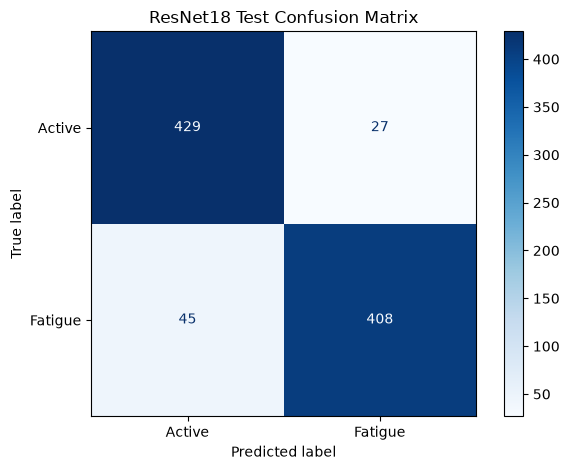

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Restore the best fine-tuned checkpoint
checkpoint = torch.load(
    BEST_FINETUNE_PATH,
    map_location=device,
    weights_only=True
)

resnet.load_state_dict(checkpoint["model_state_dict"])
resnet.to(device)
resnet.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Model device:", next(resnet.parameters()).device)

# Threshold selected from validation results
TEST_THRESHOLD = 0.50

test_true = []
test_fatigue_probs = []

# Evaluate the held-out test set
with torch.inference_mode():
    for images, labels in tqdm(
        test_loader,
        desc="ResNet18 test evaluation"
    ):
        images = images.to(device, non_blocking=True)

        outputs = resnet(images)
        probabilities = torch.softmax(outputs, dim=1)

        test_fatigue_probs.extend(
            probabilities[:, 1].cpu().numpy().tolist()
        )
        test_true.extend(labels.numpy().tolist())

test_true = np.array(test_true)
test_fatigue_probs = np.array(test_fatigue_probs)

# Apply the fixed validation-selected threshold
test_predictions = (
    test_fatigue_probs >= TEST_THRESHOLD
).astype(int)

# Calculate metrics
print(f"\nFixed threshold: {TEST_THRESHOLD:.2f}")
print(f"Test samples: {len(test_true)}")
print(f"Test accuracy: {accuracy_score(test_true, test_predictions):.4f}")
print(
    "Fatigue precision:",
    f"{precision_score(test_true, test_predictions, pos_label=1, zero_division=0):.4f}"
)
print(
    "Fatigue recall:",
    f"{recall_score(test_true, test_predictions, pos_label=1, zero_division=0):.4f}"
)
print(
    "Fatigue F1-score:",
    f"{f1_score(test_true, test_predictions, pos_label=1, zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    test_true,
    test_predictions,
    labels=[0, 1],
    target_names=["Active", "Fatigue"],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    test_true,
    test_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Active", "Fatigue"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet18 Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as show_table

RESULTS_DIR = Path(r"E:\Driver-Drowsiness\results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {
        "Model": "Custom CNN",
        "Threshold": 0.35,
        "Test Accuracy": 0.7932,
        "Fatigue Precision": 0.7874,
        "Fatigue Recall": 0.8013,
        "Fatigue F1": 0.7943,
        "Correct Predictions": 721,
        "Incorrect Predictions": 188
    },
    {
        "Model": "ResNet18 Transfer Learning",
        "Threshold": 0.50,
        "Test Accuracy": 0.9208,
        "Fatigue Precision": 0.9379,
        "Fatigue Recall": 0.9007,
        "Fatigue F1": 0.9189,
        "Correct Predictions": 837,
        "Incorrect Predictions": 72
    }
])

show_table(comparison.round(4))

comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

print("Comparison saved to:", RESULTS_DIR / "model_comparison.csv")

,Model,Threshold,Test Accuracy,Fatigue Precision,Fatigue Recall,Fatigue F1,Correct Predictions,Incorrect Predictions
0,Custom CNN,0.35,0.7932,0.7874,0.8013,0.7943,721,188
1,ResNet18 Transfer Learning,0.50,0.9208,0.9379,0.9007,0.9189,837,72


Comparison saved to: E:\Driver-Drowsiness\results\model_comparison.csv


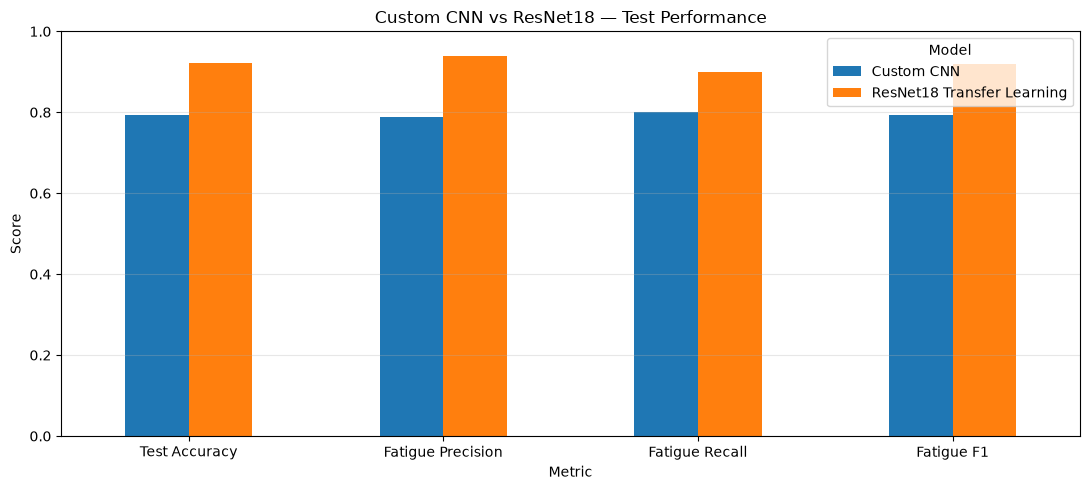

In [20]:
metrics = [
    "Test Accuracy",
    "Fatigue Precision",
    "Fatigue Recall",
    "Fatigue F1"
]

comparison_plot = comparison.set_index("Model")[metrics]

ax = comparison_plot.T.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Custom CNN vs ResNet18 — Test Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [21]:
from pathlib import Path

for split, frame in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n--- {split} filename examples ---")

    for path in frame["path"].head(12):
        print(Path(path).name)


--- TRAIN filename examples ---
img_i_1711.jpg
img_f_1740.jpg
img_k_4710.jpg
img_h_4290.jpg
image_630.jpg
img_i_14993.jpg
img_h_1650.jpg
image_12499.jpg
img_h_2220.jpg
img_k_2850.jpg
img_h_2730.jpg
img_e_14007.jpg

--- VALIDATION filename examples ---
img_k_12930.jpg
img_i_4988.jpg
img_h_18480.jpg
img_e_14703.jpg
img_b_1711.jpg
image_16153.jpg
image_0183.jpg
img_j_2784.jpg
img_k_2820.jpg
img_h_9810.jpg
image_1479.jpg
img_i_17893.jpg

--- TEST filename examples ---
img_f_3422.jpg
img_k_14550.jpg
image_1800.jpg
img_i_13891.jpg
img_h_4470.jpg
img_c_3944.jpg
img_h_12060.jpg
img_h_9930.jpg
img_i_6873.jpg
img_a_225.jpg
img_a_645.jpg
img_k_14850.jpg
